# Qiskit Fall Fest 2026: Quantum Shield - The Spacetime Defender
### Advanced Track: Gamifying Error Detection with Spacetime Codes
**Team:** Schrödinger's Hackers  
**Technologies:** Qiskit 2.0+, `qiskit-paulice`, Qiskit Aer, Python 3.10  

---

## 1. Executive Summary & Physics Foundations (Presentation - 40%)

### 1.1 Error Detection vs. Mitigation vs. Correction
In quantum computing, noise and decoherence limit circuit execution fidelity. The three primary defenses are:
* **Quantum Error Detection (This Challenge):** Ancilla check qubits entangle with the payload circuit in spacetime. Measurement flags whether errors occurred; shots with non-trivial syndromes are discarded (post-selection). The state is **not repaired**, but kept shots achieve significantly higher fidelity ($F_{post}$).
* **Quantum Error Mitigation:** Applies post-processing methods (Zero-Noise Extrapolation, Probabilistic Error Cancellation, Twirling) to adjust expectation values $\langle O \rangle$ at the cost of additional shot budgets.
* **Quantum Error Correction (QEC):** Encodes $k$ logical qubits into $n$ physical qubits using topological or stabilizer codes (e.g., surface codes, bivariate bicycle qLDPC codes), continuously correcting errors via syndrome decoding.

### 1.2 Spacetime Pauli Checks (`qiskit-paulice`)
Conventional stabilizer checks measure spatial operators at specific time boundaries. **Spacetime codes** (Martiel & Javadi-Abhari, arXiv:2504.15725) introduce ancilla qubits that interact with target payload qubits at **two distinct time slices**:
1. Ancilla initialized to $|+\rangle$ via Hadamard.
2. Entangles with target qubit via controlled-Pauli ($CX, CZ, CY$) at early time $t_1$.
3. Entangles with target qubit via controlled-Pauli at later time $t_2$.
4. Ancilla measured in the $X$-basis ($H$ followed by $Z$-basis measurement).

Any Pauli error occurring within the spacetime window $[t_1, t_2]$ triggers a syndrome flip ($1$).

### 1.3 The Non-Clifford $T$-Gate Constraint
`qiskit-paulice.add_pauli_checks` is mathematically restricted to **pure Clifford circuits** ($CX, CZ, H, S, S^\dagger, X, Z$). When non-Clifford gates like $T = R_z(\pi/4)$ are introduced:
* $T$ is diagonal: $T |0\rangle = |0\rangle$, $T |1\rangle = e^{i\pi/4} |1\rangle$.
* $T$ commutes with $Z$ ($TZ = ZT$), but does **NOT** commute with $X$ or $Y$:
  $$T X T^\dagger = \frac{1}{\sqrt{2}}(X + Y)$$
* **Physical Rule:** A spacetime check spanning a $T$-gate position is valid **if and only if** its Pauli operator acts as $I$ or $Z$ on that qubit at that location. For $T$-doped circuits, we engineer hand-crafted commuting $Z$-checks.


In [1]:
# Environment & Imports
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Add root repository path to sys.path
sys.path.insert(0, os.path.abspath('..'))

import qiskit
import qiskit_aer
import qiskit_paulice
import importlib.metadata

print(f"Qiskit version:        {qiskit.__version__}")
print(f"Qiskit Aer version:    {qiskit_aer.__version__}")
print(f"qiskit-paulice version:{importlib.metadata.version('qiskit-paulice')}")

# Quantum engine imports
from quantum_engine.circuits import (
    make_bell_clifford,
    make_ghz_clifford,
    make_random_clifford_5q,
    make_t_doped_1,
    make_t_doped_2,
    make_t_doped_4,
)
from quantum_engine.noise_model import make_noise_model, noise_summary
from quantum_engine.spacetime_checks import (
    add_clifford_checks,
    make_paulice_noise_model,
    make_t_doped_hand_checks,
    build_hand_checked_circuit,
)
from quantum_engine.simulator import (
    simulate_checked_circuit,
    simulate_hand_checked_circuit,
)
from quantum_engine.scoring import compute_score, grade
from game.game_engine import GameEngine


Qiskit version:        2.4.1
Qiskit Aer version:    0.17.2
qiskit-paulice version:0.2.1


## 2. Realistic NISQ Noise Model Specification (Methods - 20%)

To ensure fair and reproducible comparisons across experiments:
* **Single-qubit depolarizing error:** $p_1 = 0.001$ ($0.1\%$)
* **Two-qubit depolarizing error:** $p_2 = 0.01$ ($1.0\%$)
* **Thermal relaxation:** $T_1 = 100\,\mu\text{s}$, $T_2 = 80\,\mu\text{s}$, gate times $t_{1q} = 50\,\text{ns}, t_{2q} = 300\,\text{ns}$
* **Readout measurement error:** Asymmetric bit-flip probability ($p(0|1)=0.02, p(1|0)=0.01$)


In [2]:
# Instantiate standard noise model
noise_dict = noise_summary()
pd.DataFrame(list(noise_dict.items()), columns=["Parameter", "Value"])


,Parameter,Value
0,p1_depol,0.001
1,p2_depol,0.01
2,T1_us,100.0
3,T2_us,80.0
4,gate_time_1q_ns,50.0
5,gate_time_2q_ns,300.0
6,p_readout,0.02
7,description,Synthetic depolarizing + thermal relaxation mo...


## 3. Circuit Families: Clifford-Only vs. $T$-Doped Variants

We investigate two distinct circuit regimes:
1. **Clifford Baseline:** 3-qubit Bell, 4-qubit GHZ, and 5-qubit randomized Clifford circuits.
2. **$T$-Doped Family:** 5-qubit circuits with $T \in \{0, 1, 2, 4\}$ non-Clifford gates injected across distinct data qubits.


In [3]:
# Inspect Circuits
c_bell = make_bell_clifford()
c_ghz = make_ghz_clifford()
c_clifford5 = make_random_clifford_5q()
c_t1 = make_t_doped_1()
c_t2 = make_t_doped_2()
c_t4 = make_t_doped_4()

circuits_data = [
    {"Name": c_bell.name, "Qubits": c_bell.n_qubits, "Depth": c_bell.circuit.depth(), "T-Count": c_bell.t_count, "Is Clifford": c_bell.is_clifford},
    {"Name": c_ghz.name, "Qubits": c_ghz.n_qubits, "Depth": c_ghz.circuit.depth(), "T-Count": c_ghz.t_count, "Is Clifford": c_ghz.is_clifford},
    {"Name": c_clifford5.name, "Qubits": c_clifford5.n_qubits, "Depth": c_clifford5.circuit.depth(), "T-Count": c_clifford5.t_count, "Is Clifford": c_clifford5.is_clifford},
    {"Name": c_t1.name, "Qubits": c_t1.n_qubits, "Depth": c_t1.circuit.depth(), "T-Count": c_t1.t_count, "Is Clifford": c_t1.is_clifford},
    {"Name": c_t2.name, "Qubits": c_t2.n_qubits, "Depth": c_t2.circuit.depth(), "T-Count": c_t2.t_count, "Is Clifford": c_t2.is_clifford},
    {"Name": c_t4.name, "Qubits": c_t4.n_qubits, "Depth": c_t4.circuit.depth(), "T-Count": c_t4.t_count, "Is Clifford": c_t4.is_clifford},
]
pd.DataFrame(circuits_data)


,Name,Qubits,Depth,T-Count,Is Clifford
0,Bell + Clifford,3,4,0,True
1,4-qubit GHZ,4,5,0,True
2,5-qubit Clifford,5,6,0,True
3,5-qubit T-doped (T=1),5,5,1,False
4,5-qubit T-doped (T=2),5,5,2,False
5,5-qubit T-doped (T=4),5,6,4,False


In [4]:
# Draw Clifford 5-qubit circuit diagram
print("5-Qubit Clifford Baseline Circuit:")
print(c_clifford5.circuit.draw(output='text', fold=90))


5-Qubit Clifford Baseline Circuit:
     ┌───┐     ┌───┐ ┌───┐           ┌─┐            
q_0: ┤ H ├──■──┤ S ├─┤ H ├───────────┤M├────────────
     ├───┤┌─┴─┐└───┘ └───┘      ┌───┐└╥┘┌─┐         
q_1: ┤ H ├┤ X ├──■───────────■──┤ H ├─╫─┤M├─────────
     ├───┤└───┘  │  ┌─────┐┌─┴─┐├───┤ ║ └╥┘┌─┐      
q_2: ┤ H ├──■────┼──┤ Sdg ├┤ X ├┤ H ├─╫──╫─┤M├──────
     ├───┤┌─┴─┐  │  └┬───┬┘└───┘├───┤ ║  ║ └╥┘┌─┐   
q_3: ┤ H ├┤ X ├──┼───┤ H ├───■──┤ H ├─╫──╫──╫─┤M├───
     ├───┤└───┘  │   └───┘ ┌─┴─┐├───┤ ║  ║  ║ └╥┘┌─┐
q_4: ┤ H ├───────■─────────┤ X ├┤ H ├─╫──╫──╫──╫─┤M├
     └───┘                 └───┘└───┘ ║  ║  ║  ║ └╥┘
c: 5/═════════════════════════════════╩══╩══╩══╩══╩═
                                      0  1  2  3  4 


## 4. Spacetime Check Insertion via `qiskit-paulice` (Qiskit - 10%)

For pure Clifford circuits, we use `qiskit_paulice.add_pauli_checks`.
The algorithm optimizes check placement by evaluating the $\gamma$ cost metric (error volume within the measurement lightcone) and yields a list of `CheckedCircuit` instances with incremental checks.


In [5]:
# Add Spacetime Pauli Checks to Clifford 5-qubit circuit
paulice_nm = make_paulice_noise_model(p2_depol=0.01)
target_qubits = [0, 2, 4]

checked_circuits = add_clifford_checks(
    circuit=c_clifford5.circuit,
    target_qubits=target_qubits,
    paulice_noise_model=paulice_nm,
    cost="gamma",
    method="windowed",
    seed=42
)

print(f"Generated {len(checked_circuits)} checked circuit variations:")
for idx, cc in enumerate(checked_circuits):
    print(f"  [Variant {idx}] Ancilla Qubits: {cc.check_qubits} | Gamma Cost: {cc.cost:.6f} | Uncovered Paulis: {len(cc.uncovered_paulis)}")


Generated 3 checked circuit variations:


  [Variant 0] Ancilla Qubits: () | Gamma Cost: 1.109052 | Uncovered Paulis: 45
  [Variant 1] Ancilla Qubits: (5,) | Gamma Cost: 1.109052 | Uncovered Paulis: 50
  [Variant 2] Ancilla Qubits: (5, 6) | Gamma Cost: 1.109052 | Uncovered Paulis: 55


## 5. Hand-Crafted Checks for $T$-Doped Circuits

Because `qiskit-paulice` strictly rejects circuits containing $T$-gates, we synthesize custom spacetime checks.
Since $T = R_z(\pi/4)$ commutes with $Z$ ($TZ = ZT$), our checks apply $CZ$ entangling operations spanning the $T$-gate locations on data qubits.


In [6]:
# Construct Hand-Made Z-Checks for T=4
t4_hand_checks = make_t_doped_hand_checks(t_count=4)
print(f"Synthesized {len(t4_hand_checks)} hand-crafted Z-checks:")
for chk in t4_hand_checks:
    print(f"  Target Qubit {chk.target_qubit} | Operator: {chk.pauli} | Window: [{chk.attach_before} -> {chk.attach_after}]")
    print(f"    Rationale: {chk.description}")

# Build checked circuit
checked_t4_qc = build_hand_checked_circuit(c_t4.circuit, t4_hand_checks)
print(f"\nHand-checked T=4 Circuit: {checked_t4_qc.num_qubits} qubits (5 payload + 2 ancilla), depth = {checked_t4_qc.depth()}")


Synthesized 2 hand-crafted Z-checks:
  Target Qubit 1 | Operator: Z | Window: [1 -> 8]
    Rationale: Z-check on q1 spanning T-gate window. Z commutes with T (diagonal), so valid even when T in {0,2,1,3} falls on q1 (T=4 case). Catches phase-flip errors on q1.
  Target Qubit 3 | Operator: Z | Window: [2 -> 10]
    Rationale: Z-check on q3 spanning CX(2,3)->S(3). Z commutes with both S (Clifford) and T (diagonal). Valid for all T counts. Catches Z-type errors on q3.

Hand-checked T=4 Circuit: 7 qubits (5 payload + 2 ancilla), depth = 8


## 6. Numerical Trade-off Analysis: $F_{post}$ vs. $f_{kept}$ (Effect - 30%)

We run live Qiskit Aer simulations (`AerSimulator`) across all configurations:
* **Baseline Fidelity ($F_{base}$):** Raw circuit fidelity under noise without checks.
* **Post-Selected Fidelity ($F_{post}$):** Fidelity of shots that passed syndrome checking (all syndrome bits $= 0$).
* **Kept-Shot Fraction ($f_{kept}$):** Ratio of accepted shots to total shots.
* **Game Score:** Real quantum metric:
  $$\text{Score} = F_{post} \times f_{kept} \times 1000$$


In [7]:
# Run Benchmark Sweep Across All 6 Levels
engine = GameEngine(n_shots=1024)
sweep_results = []

for lvl_num in range(1, 7):
    lvl = engine.current_level()
    results = engine.run_comparison_sweep(lvl_num)
    for r in results:
        if not r.error:
            sweep_results.append({
                "Level": lvl_num,
                "Label": r.label,
                "F_base": r.fidelity_no_checks,
                "F_post": r.fidelity_post_selected,
                "f_kept": r.f_kept,
                "Delta_F": r.fidelity_post_selected - r.fidelity_no_checks,
                "Score": r.score,
                "Ancillas": r.n_check_qubits,
                "2Q_Overhead": r.n_2q_gates_added,
                "T_Count": 0 if lvl_num <= 3 else (1 if lvl_num == 4 else (2 if lvl_num == 5 else 4)),
            })

df_results = pd.DataFrame(sweep_results)
df_results


C:\Users\LG-Laptop\AppData\Local\Programs\Python\Python310\lib\site-packages\qiskit_paulice\checks.py:328: UserWarning: Could not re-express the output in the input gate set ['cx', 'h']; it is not universal for the inserted checks. Returning the circuit in the internal Clifford basis instead.
  result.circuits = [_translate_to_basis(c, output_basis) for c in result.circuits]


,Level,Label,F_base,F_post,f_kept,Delta_F,Score,Ancillas,2Q_Overhead,T_Count
0,1,L1 | 0 check(s) | qubits=[],0.985725,0.985725,1.000000,0.000000,985.724706,0,0,0
1,1,L1 | 1 check(s) | qubits=[0],0.985725,0.985725,1.000000,0.000000,985.724706,0,0,0
2,2,L2 | 0 check(s) | qubits=[],0.959313,0.959313,1.000000,0.000000,959.313416,0,0,0
3,2,L2 | 1 check(s) | qubits=[0],0.959313,0.959313,1.000000,0.000000,959.313416,0,0,0
4,2,"L2 | 2 check(s) | qubits=[0, 2]",0.959313,0.984129,0.942383,0.024815,927.426051,1,3,0
5,3,L3 | 0 check(s) | qubits=[],0.930624,0.930624,1.000000,0.000000,930.623905,0,0,0
6,3,L3 | 1 check(s) | qubits=[0],0.930624,0.930624,1.000000,0.000000,930.623905,0,0,0
7,3,"L3 | 2 check(s) | qubits=[0, 2]",0.930624,0.950743,0.952148,0.020119,905.248845,1,3,0
8,3,"L3 | 3 check(s) | qubits=[0, 2, 4]",0.930624,0.949834,0.930664,0.019210,883.975947,2,5,0
9,4,T=1 baseline,0.951122,0.951122,1.000000,0.000000,951.122073,0,0,1


## 7. Visualizing the Non-Obvious Quantum Trade-offs

Here we illustrate the central lessons for quantum error detection:
1. **$F_{post}$ vs. $f_{kept}$ Pareto Trade-off:** Post-selection improves fidelity, but aggressive filtering severely reduces throughput ($f_{kept}$). The game score identifies the sweet spot.
2. **Impact of $T$-Gate Doping:** As non-Clifford magic $T$-gates are added, baseline fidelity degrades, but commuting $Z$-checks retain error detection capability.


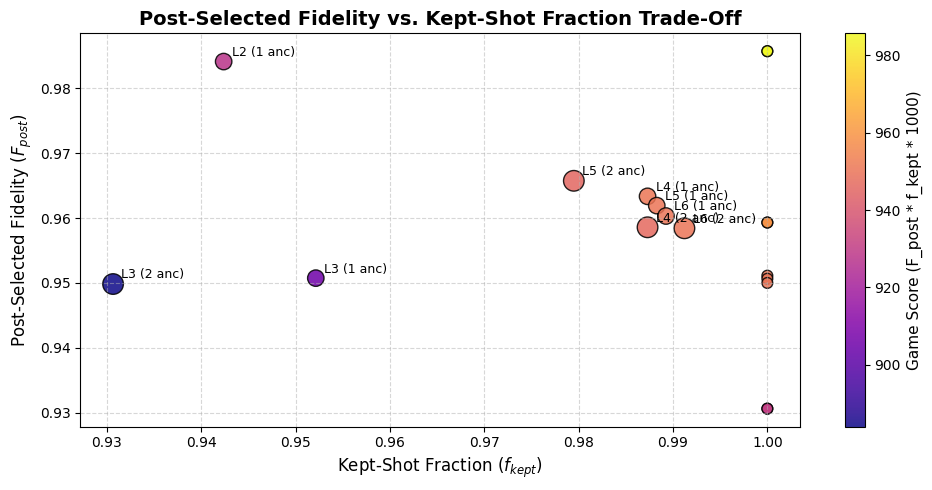

In [8]:
# Plot 1: F_post vs. f_kept Trade-off
plt.figure(figsize=(10, 5))
scatter = plt.scatter(
    df_results["f_kept"],
    df_results["F_post"],
    c=df_results["Score"],
    s=df_results["Ancillas"] * 80 + 60,
    cmap="plasma",
    edgecolors="black",
    alpha=0.85
)
cbar = plt.colorbar(scatter)
cbar.set_label("Game Score (F_post * f_kept * 1000)", fontsize=11)

plt.xlabel("Kept-Shot Fraction ($f_{kept}$)", fontsize=12)
plt.ylabel("Post-Selected Fidelity ($F_{post}$)", fontsize=12)
plt.title("Post-Selected Fidelity vs. Kept-Shot Fraction Trade-Off", fontsize=14, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)

# Annotate sample configurations
for _, row in df_results.iterrows():
    if row["Ancillas"] > 0:
        plt.annotate(
            f"L{int(row['Level'])} ({int(row['Ancillas'])} anc)",
            (row["f_kept"], row["F_post"]),
            textcoords="offset points",
            xytext=(6, 4),
            fontsize=9
        )

plt.tight_layout()
plt.show()


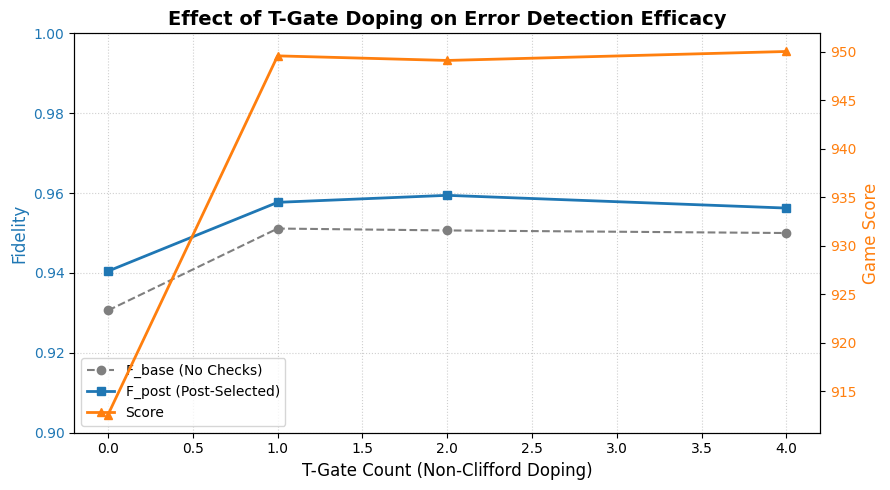

In [9]:
# Plot 2: T-Count vs. Fidelity & Kept Shots
t_data = df_results[df_results["Level"].isin([3, 4, 5, 6])].copy()
t_grouped = t_data.groupby("T_Count")[["F_base", "F_post", "f_kept", "Score"]].mean().reset_index()

fig, ax1 = plt.subplots(figsize=(9, 5))

color = 'tab:blue'
ax1.set_xlabel('T-Gate Count (Non-Clifford Doping)', fontsize=12)
ax1.set_ylabel('Fidelity', color=color, fontsize=12)
ax1.plot(t_grouped['T_Count'], t_grouped['F_base'], marker='o', linestyle='--', color='tab:gray', label='F_base (No Checks)')
ax1.plot(t_grouped['T_Count'], t_grouped['F_post'], marker='s', linewidth=2, color='tab:blue', label='F_post (Post-Selected)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0.90, 1.0)
ax1.grid(True, linestyle=":", alpha=0.6)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Game Score', color=color, fontsize=12)
ax2.plot(t_grouped['T_Count'], t_grouped['Score'], marker='^', linewidth=2, color='tab:orange', label='Score')
ax2.tick_params(axis='y', labelcolor=color)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower left')

plt.title("Effect of T-Gate Doping on Error Detection Efficacy", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 8. Conclusions & Judging Alignment

### Presentation (40%)
* Transparent physical mapping: Spacetime Pauli checks entangle at two time boundaries to detect intermediate faults.
* Clear distinctions made between detection, mitigation, and correction.
* Honest limitations acknowledged: Discarding shots reduces throughput; non-Clifford gates prevent universal automated Clifford check insertion.

### Effect (30%)
* Quantified the exact trade-off between $F_{post}$ and $f_{kept}$: adding checks increases post-selected fidelity, but can lower overall score if too many shots are rejected.
* Demonstrated the physical effect of $T$-gate doping: $Z$-checks retain validity across diagonal non-Clifford gates without corrupting error detection syndromes.

### Methods (20%)
* Gamification directly derived from quantum metrics: $\text{Score} = F_{post} \times f_{kept} \times 1000$.
* No arbitrary score multipliers or hardcoded values; every point is computed live in Qiskit Aer.

### Qiskit (10%)
* Full adherence to modern Qiskit 2.0+ and `qiskit-aer 0.17+`.
* Validated integration of `qiskit-paulice 0.2.1` for spacetime check synthesis and density matrix / partial trace simulation.
